# Effective Population Size from Generation Records

If we observe each generation, how can we measure the strength of drift?
Use the same simulated cultures as the first notebook. The records contain
complete population frequencies in generations 0–19. They have no additional
genotype-sampling error, mutation, migration, or selection.

For parental frequency $p$, define

$$c_V=\frac{\operatorname{Var}(p_{t+1}-p_t\mid p_t=p)}{p(1-p)},
\qquad N_e^{(V)}=\frac{1}{2c_V}.$$

Repeated cultures starting at the same $p$ let us estimate this conditional
variance. One culture's change alone does not provide it.


In [1]:
library(hpgR)
generation_records <- simulateFrequencyRecords()$records


## Read the Generation Records

The code above regenerates the first notebook's records with the same seed,
so this notebook also runs independently. Rows are known generations and
columns are independent cultures. Inspect the first six cultures.


In [2]:
options(repr.plot.width = 9, repr.plot.height = 4.2, repr.plot.pointsize = 13,
        repr.plot.bg = "white")
invisible(par(bg = "white"))
blue <- "#265991"
red <- "#C73D28"
data.frame(generation = generation_records$generation[1:4],
           generation_records$frequency[1:4, 1:6], check.names = FALSE)


generation,1,2,3,4,5,6
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0,0.50000,0.50000,0.50000,0.50000,0.50000,0.50000
1,0.34375,0.40625,0.50000,0.40625,0.46875,0.40625
2,0.37500,0.25000,0.53125,0.34375,0.25000,0.40625
3,0.31250,0.12500,0.56250,0.28125,0.40625,0.40625


## Estimate the Copying Rate within a Frequency Class

Every culture starts at $p_0=0.5$. Use the first recorded transition across
cultures to estimate $s_p^2=\widehat{\operatorname{Var}}(p_1-p_0\mid p_0=0.5)$.
Then $\widehat N_e^{(V)}=p_0(1-p_0)/(2s_p^2)$.
Later transitions have different parental frequencies and must be grouped
by their starting frequency before applying this same calculation.


In [3]:

parent_frequency <- generation_records$frequency[1, ]
offspring_frequency <- generation_records$frequency[2, ]
estimate <- estimateFromGenerations(parent_frequency, offspring_frequency)
round(estimate, 5)


parental_p transitions    variance         c_V        Ne_V 
    0.50000   105.00000     0.00778     0.03111    16.07360

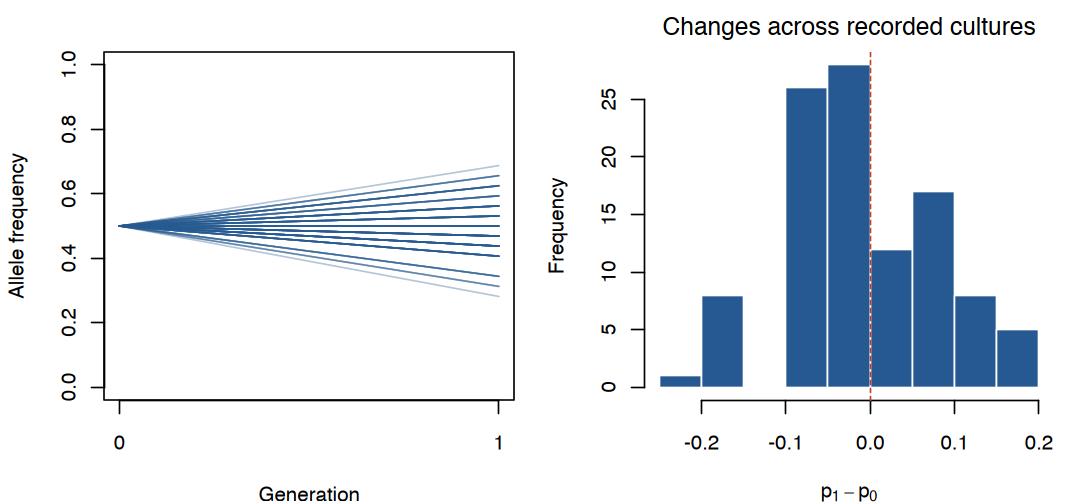

In [4]:
old_par <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1), bg = "white")
matplot(0:1, rbind(parent_frequency, offspring_frequency), type = "l",
        col = grDevices::adjustcolor(blue, alpha.f = 0.35), lty = 1,
        xlab = "Generation", ylab = "Allele frequency", xaxt = "n", ylim = c(0, 1))
axis(1, at = 0:1)
hist(offspring_frequency - parent_frequency, breaks = 12, col = blue, border = "white",
     xlab = expression(p[1] - p[0]), main = "Changes across recorded cultures")
abline(v = 0, col = red, lty = 2)
par(old_par)


## Compare with the Generating Size

The estimate used only the two recorded frequencies. Now reveal the known
simulation size. Finite replication makes the estimated variance noisy.
Buri's experiment in the lecture uses the same variance-matching principle;
these simulated records do not reproduce his observed estimates.


In [5]:
generating_N <- generation_records$generating_N
data.frame(
    quantity = c("Conditional frequency variance", "Variance effective size"),
    estimated = c(estimate["variance"], estimate["Ne_V"]),
    generating_model = c(0.5 * 0.5 / (2 * generating_N), generating_N)
)
stopifnot(abs(var(offspring_frequency - parent_frequency) - var(offspring_frequency)) < 1e-12)


,quantity,estimated,generating_model
,<chr>,<dbl>,<dbl>
variance,Conditional frequency variance,0.007776728,0.0078125
Ne_V,Variance effective size,16.073597056,16.0000000


Sources: Pritchard, [Sec. 2.1](https://web.stanford.edu/group/pritchardlab/HGbook.html);
Gorroochurn, Sec. 8.8; Buri (1956), Table 11 and Fig. 3.
This calculation requires time-indexed frequencies. Lecture 9 estimates
population parameters from sampled genetic data without these generation records.
